# Waste Hotspot Detection Using DBSCAN

## A Citizen-Based Waste Reporting System for Waste Hotspot Detection and Collection Route Optimization Using DBSCAN

### Case Study: Mzuzu City, Malawi

This notebook develops the Data Science component of the project.

The objective is to use geographically referenced citizen waste reports to identify spatial clusters of waste reports, which will be treated as waste hotspots.

The DBSCAN algorithm will be used because it can identify dense spatial clusters without requiring the number of clusters to be specified in advance.

## 1. Objective

The objective of this notebook is to:

1. Load geographically referenced waste reports.
2. Explore the spatial distribution of the reports.
3. Apply the DBSCAN clustering algorithm.
4. Identify waste hotspots.
5. Identify isolated waste reports as noise.
6. Analyze the types of waste problems within each hotspot.
7. Visualize the detected hotspots on a map.
8. Prepare hotspot information for the later route optimization component.

In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import folium

In [2]:
data = {
    "report_id": [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10,
        11, 12, 13, 14, 15
    ],

    "latitude": [
        -11.45810,
        -11.45820,
        -11.45830,
        -11.45815,
        -11.45825,

        -11.46100,
        -11.46110,
        -11.46090,
        -11.46105,
        -11.46095,

        -11.47000,
        -11.48000,
        -11.49000,
        -11.50000,
        -11.51000
    ],

    "longitude": [
        34.02050,
        34.02060,
        34.02040,
        34.02070,
        34.02055,

        34.02500,
        34.02510,
        34.02490,
        34.02520,
        34.02480,

        34.04000,
        34.05000,
        34.06000,
        34.07000,
        34.08000
    ],

    "category": [
        "Overflowing bin",
        "Illegal dumping",
        "Scattered waste",
        "Overflowing bin",
        "Illegal dumping",

        "Overflowing bin",
        "Illegal dumping",
        "Scattered waste",
        "Overflowing bin",
        "Illegal dumping",

        "Scattered waste",
        "Illegal dumping",
        "Overflowing bin",
        "Scattered waste",
        "Illegal dumping"
    ]
}


df = pd.DataFrame(data)

In [3]:
df

,report_id,latitude,longitude,category
0,1,-11.45810,34.02050,Overflowing bin
1,2,-11.45820,34.02060,Illegal dumping
2,3,-11.45830,34.02040,Scattered waste
3,4,-11.45815,34.02070,Overflowing bin
4,5,-11.45825,34.02055,Illegal dumping
5,6,-11.46100,34.02500,Overflowing bin
6,7,-11.46110,34.02510,Illegal dumping
7,8,-11.46090,34.02490,Scattered waste
8,9,-11.46105,34.02520,Overflowing bin
9,10,-11.46095,34.02480,Illegal dumping


In [4]:
print("Number of waste reports:", len(df))

Number of waste reports: 15


In [5]:
print("Columns:")
df.columns

Columns:


Index(['report_id', 'latitude', 'longitude', 'category'], dtype='object')

In [6]:
df.isnull().sum()

report_id    0
latitude     0
longitude    0
category     0
dtype: int64

In [7]:
df["category"].value_counts()

category
Illegal dumping    6
Overflowing bin    5
Scattered waste    4
Name: count, dtype: int64

In [8]:
coordinates = df[["latitude", "longitude"]].to_numpy()

coordinates

array([[-11.4581 ,  34.0205 ],
       [-11.4582 ,  34.0206 ],
       [-11.4583 ,  34.0204 ],
       [-11.45815,  34.0207 ],
       [-11.45825,  34.02055],
       [-11.461  ,  34.025  ],
       [-11.4611 ,  34.0251 ],
       [-11.4609 ,  34.0249 ],
       [-11.46105,  34.0252 ],
       [-11.46095,  34.0248 ],
       [-11.47   ,  34.04   ],
       [-11.48   ,  34.05   ],
       [-11.49   ,  34.06   ],
       [-11.5    ,  34.07   ],
       [-11.51   ,  34.08   ]])

In [9]:
coordinates_radians = np.radians(coordinates)

coordinates_radians

array([[-0.19998157,  0.59376974],
       [-0.19998332,  0.59377148],
       [-0.19998506,  0.59376799],
       [-0.19998244,  0.59377323],
       [-0.19998419,  0.59377061],
       [-0.20003219,  0.59384828],
       [-0.20003393,  0.59385002],
       [-0.20003044,  0.59384653],
       [-0.20003306,  0.59385177],
       [-0.20003131,  0.59384479],
       [-0.20018927,  0.59411008],
       [-0.2003638 ,  0.59428461],
       [-0.20053833,  0.59445914],
       [-0.20071286,  0.59463368],
       [-0.2008874 ,  0.59480821]])

In [10]:
# Maximum distance between neighboring reports
# 200 metres = 0.2 kilometres

eps_km = 0.2

# Convert kilometres to radians
earth_radius_km = 6371.0088

eps_radians = eps_km / earth_radius_km

# Minimum number of reports required to form a cluster
min_samples = 3

In [11]:
dbscan = DBSCAN(
    eps=eps_radians,
    min_samples=min_samples,
    metric="haversine"
)

cluster_labels = dbscan.fit_predict(coordinates_radians)

In [12]:
df["cluster"] = cluster_labels

df

,report_id,latitude,longitude,category,cluster
0,1,-11.45810,34.02050,Overflowing bin,0
1,2,-11.45820,34.02060,Illegal dumping,0
2,3,-11.45830,34.02040,Scattered waste,0
3,4,-11.45815,34.02070,Overflowing bin,0
4,5,-11.45825,34.02055,Illegal dumping,0
5,6,-11.46100,34.02500,Overflowing bin,1
6,7,-11.46110,34.02510,Illegal dumping,1
7,8,-11.46090,34.02490,Scattered waste,1
8,9,-11.46105,34.02520,Overflowing bin,1
9,10,-11.46095,34.02480,Illegal dumping,1


In [13]:
number_of_clusters = len(
    set(cluster_labels)
) - (1 if -1 in cluster_labels else 0)

print("Number of waste hotspots:", number_of_clusters)

Number of waste hotspots: 2


In [14]:
number_of_noise_points = list(cluster_labels).count(-1)

print("Number of isolated/noise reports:", number_of_noise_points)

Number of isolated/noise reports: 5


In [15]:
cluster_counts = df["cluster"].value_counts().sort_index()

cluster_counts

cluster
-1    5
 0    5
 1    5
Name: count, dtype: int64

In [16]:
hotspot_reports = df[df["cluster"] != -1].copy()

hotspot_reports

,report_id,latitude,longitude,category,cluster
0,1,-11.45810,34.02050,Overflowing bin,0
1,2,-11.45820,34.02060,Illegal dumping,0
2,3,-11.45830,34.02040,Scattered waste,0
3,4,-11.45815,34.02070,Overflowing bin,0
4,5,-11.45825,34.02055,Illegal dumping,0
5,6,-11.46100,34.02500,Overflowing bin,1
6,7,-11.46110,34.02510,Illegal dumping,1
7,8,-11.46090,34.02490,Scattered waste,1
8,9,-11.46105,34.02520,Overflowing bin,1
9,10,-11.46095,34.02480,Illegal dumping,1


In [17]:
hotspot_summary = (
    hotspot_reports
    .groupby("cluster")
    .agg(
        number_of_reports=("report_id", "count"),
        average_latitude=("latitude", "mean"),
        average_longitude=("longitude", "mean")
    )
    .reset_index()
)

hotspot_summary

,cluster,number_of_reports,average_latitude,average_longitude
0,0,5,-11.4582,34.02055
1,1,5,-11.4610,34.02500


In [18]:
hotspot_categories = (
    hotspot_reports
    .groupby(["cluster", "category"])
    .size()
    .reset_index(name="number_of_reports")
)

hotspot_categories

,cluster,category,number_of_reports
0,0,Illegal dumping,2
1,0,Overflowing bin,2
2,0,Scattered waste,1
3,1,Illegal dumping,2
4,1,Overflowing bin,2
5,1,Scattered waste,1


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# Calculate the main dashboard indicators
total_reports = len(df)

# Count distinct clusters, excluding -1 (noise)
total_hotspots = df.loc[df["cluster"] != -1, "cluster"].nunique()

# Count reports classified as noise
isolated_reports = int((df["cluster"] == -1).sum())

# Calculate percentage of reports assigned to clusters
clustered_percentage = (
    ((total_reports - isolated_reports) / total_reports) * 100
    if total_reports > 0 else 0
)

# Display the indicators
print("=" * 45)
print("       MZUZU SMARTCLEAN SUMMARY")
print("=" * 45)
print(f"Total waste reports:       {total_reports}")
print(f"Detected spatial clusters: {total_hotspots}")
print(f"Reports classified as noise: {isolated_reports}")
print(f"Reports in clusters:       {clustered_percentage:.1f}%")
print("=" * 45)

       MZUZU SMARTCLEAN SUMMARY
Total waste reports:       15
Detected spatial clusters: 2
Reports classified as noise: 5
Reports in clusters:       66.7%


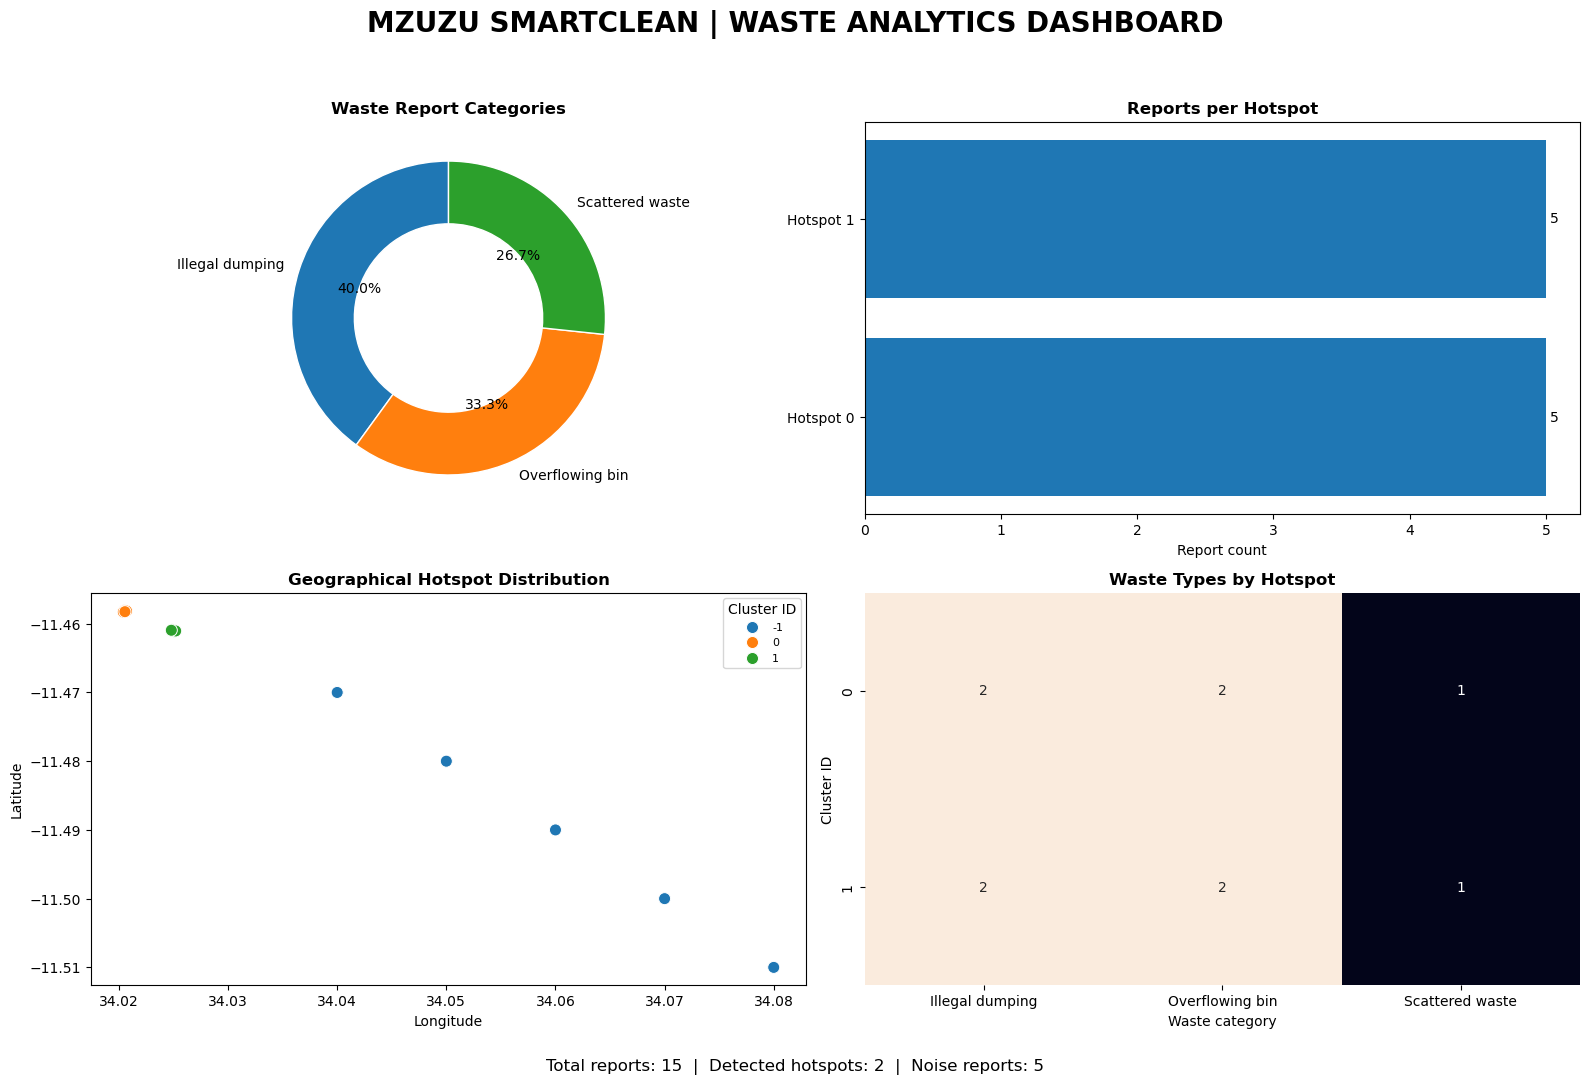

In [21]:
# Prepare the data for the dashboard
category_counts = df["category"].value_counts()

cluster_counts = (
    df.loc[df["cluster"] != -1, "cluster"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    "MZUZU SMARTCLEAN | WASTE ANALYTICS DASHBOARD",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# Chart 1: Category donut chart
axes[0, 0].pie(
    category_counts.values,
    labels=category_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)
axes[0, 0].set_title("Waste Report Categories", fontweight="bold")

# Chart 2: Number of reports per cluster
if not cluster_counts.empty:
    bars = axes[0, 1].barh(
        [f"Hotspot {i}" for i in cluster_counts.index],
        cluster_counts.values
    )
    axes[0, 1].bar_label(bars, padding=3)
    axes[0, 1].set_title("Reports per Hotspot", fontweight="bold")
    axes[0, 1].set_xlabel("Report count")
else:
    axes[0, 1].text(
        0.5, 0.5, "No hotspots detected",
        ha="center", va="center"
    )
    axes[0, 1].set_title("Reports per Hotspot", fontweight="bold")

# Chart 3: Geographic distribution of reports
sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="cluster",
    palette="tab10",
    s=75,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Geographical Hotspot Distribution",
                     fontweight="bold")
axes[1, 0].set_xlabel("Longitude")
axes[1, 0].set_ylabel("Latitude")
axes[1, 0].legend(title="Cluster ID", fontsize=8)

# Chart 4: Category counts by hotspot
clustered_data = df[df["cluster"] != -1]

if not clustered_data.empty:
    heatmap_data = pd.crosstab(
        clustered_data["cluster"],
        clustered_data["category"]
    )
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt="d",
        ax=axes[1, 1],
        cbar=False
    )
    axes[1, 1].set_title("Waste Types by Hotspot", fontweight="bold")
    axes[1, 1].set_xlabel("Waste category")
    axes[1, 1].set_ylabel("Cluster ID")
else:
    axes[1, 1].text(
        0.5, 0.5, "No hotspots to compare",
        ha="center", va="center"
    )
    axes[1, 1].set_title("Waste Types by Hotspot", fontweight="bold")

# Add a compact summary below the dashboard
fig.text(
    0.5, 0.015,
    f"Total reports: {total_reports}  |  "
    f"Detected hotspots: {total_hotspots}  |  "
    f"Noise reports: {isolated_reports}",
    ha="center",
    fontsize=12
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.savefig(
    "mzuzu_smartclean_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [23]:
import requests
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Public GIS layer containing Malawi district and city-council polygons
boundary_url = (
    "https://services.arcgis.com/uHAHKfH1Z5ye1Oe0/"
    "ArcGIS/rest/services/Malawi_REDD_paper_data/"
    "FeatureServer/0/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

response = requests.get(boundary_url, params=params, timeout=60)
response.raise_for_status()

boundary_geojson = response.json()

# Convert downloaded geographic features into a GeoDataFrame
boundary_data = gpd.GeoDataFrame.from_features(
    boundary_geojson["features"],
    crs="EPSG:4326"
)

print("Boundary data loaded successfully.")
print("Number of geographic areas:", len(boundary_data))
print("Available columns:")
print(boundary_data.columns.tolist())

Boundary data loaded successfully.
Number of geographic areas: 32
Available columns:
['geometry', 'OBJECTID', 'Shape_Leng', 'ADM2_EN', 'ADM2_PCODE', 'ADM2_REF', 'ADM2ALT1EN', 'ADM2ALT2EN', 'ADM1_EN', 'ADM1_PCODE', 'ADM0_EN', 'ADM0_PCODE', 'date', 'validOn', 'validTo', 'Shape__Area', 'Shape__Length']


In [24]:
print(boundary_data["ADM2_EN"].sort_values().to_list())

['Balaka', 'Blantyre', 'Blantyre City', 'Chikwawa', 'Chiradzulu', 'Chitipa', 'Dedza', 'Dowa', 'Karonga', 'Kasungu', 'Likoma', 'Lilongwe', 'Lilongwe City', 'Machinga', 'Mangochi', 'Mchinji', 'Mulanje', 'Mwanza', 'Mzimba', 'Mzuzu City', 'Neno', 'Nkhata Bay', 'Nkhotakota', 'Nsanje', 'Ntcheu', 'Ntchisi', 'Phalombe', 'Rumphi', 'Salima', 'Thyolo', 'Zomba', 'Zomba City']


In [25]:
# Select the geographical area whose name contains "Mzuzu"
mzuzu_boundary_data = boundary_data[
    boundary_data["ADM2_EN"].astype(str).str.contains(
        "Mzuzu", case=False, na=False
    )
].copy()

display(mzuzu_boundary_data[["ADM2_EN", "ADM2_PCODE"]])

if mzuzu_boundary_data.empty:
    print("Mzuzu was not found. Check the available area names.")
elif len(mzuzu_boundary_data) > 1:
    print("More than one match was found. Inspect the names before proceeding.")
else:
    mzuzu_boundary = mzuzu_boundary_data.geometry.iloc[0]
    print("Mzuzu boundary polygon selected.")

,ADM2_EN,ADM2_PCODE
19,Mzuzu City,MW107


Mzuzu boundary polygon selected.


In [26]:
# ============================================================
# MZUZU SMARTCLEAN
# PROFESSIONAL WASTE HOTSPOT MAP
# ============================================================
#
# This map:
# 1. Uses OpenStreetMap - NO API KEY REQUIRED
# 2. Shows the Mzuzu City boundary clearly
# 3. Shows all waste reports
# 4. Shows all DBSCAN hotspots
# 5. Shows hotspot centres
# 6. Shows a legend
# 7. Shows street names from OpenStreetMap
# 8. Saves the final map as an HTML file
#
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import folium
import pandas as pd

from shapely.geometry import Point

from folium.plugins import Fullscreen


# ------------------------------------------------------------
# 2. CHECK THAT THE REQUIRED DATA EXISTS
# ------------------------------------------------------------

print("Checking required data...")

# Check that df exists
try:
    df
    print("✓ Waste report data found.")
except NameError:
    raise NameError(
        "The DataFrame 'df' was not found. "
        "Run the cell where you created your waste report data first."
    )


# Check that mzuzu_boundary_data exists
try:
    mzuzu_boundary_data
    print("✓ Mzuzu boundary data found.")
except NameError:
    raise NameError(
        "The variable 'mzuzu_boundary_data' was not found. "
        "Run the cell where you loaded the Mzuzu boundary first."
    )


# ------------------------------------------------------------
# 3. MAKE A COPY OF THE WASTE DATA
# ------------------------------------------------------------

map_df = df.copy()


# ------------------------------------------------------------
# 4. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "latitude",
    "longitude"
]

for column in required_columns:

    if column not in map_df.columns:

        raise ValueError(
            f"The column '{column}' is missing from df."
        )


# ------------------------------------------------------------
# 5. MAKE SURE LATITUDE AND LONGITUDE ARE NUMERIC
# ------------------------------------------------------------

map_df["latitude"] = pd.to_numeric(
    map_df["latitude"],
    errors="coerce"
)

map_df["longitude"] = pd.to_numeric(
    map_df["longitude"],
    errors="coerce"
)


# Remove reports where coordinates are missing
map_df = map_df.dropna(
    subset=["latitude", "longitude"]
).copy()


print(
    f"✓ {len(map_df)} waste reports have valid coordinates."
)


# ------------------------------------------------------------
# 6. PREPARE THE MZUZU CITY BOUNDARY
# ------------------------------------------------------------

# Convert the boundary to latitude/longitude coordinates.
# EPSG:4326 is the normal geographic coordinate system
# used by web maps.

boundary_gdf = mzuzu_boundary_data.to_crs(
    "EPSG:4326"
).copy()


# ------------------------------------------------------------
# 7. COMBINE THE BOUNDARY GEOMETRIES
# ------------------------------------------------------------

# A boundary dataset can sometimes contain several polygons.
# union_all() combines them into one city boundary.

city_polygon = boundary_gdf.geometry.union_all()


# ------------------------------------------------------------
# 8. FIND A GOOD CENTRE FOR THE MAP
# ------------------------------------------------------------

centre_point = city_polygon.representative_point()

map_latitude = centre_point.y
map_longitude = centre_point.x


print(
    f"Map centre: "
    f"{map_latitude:.6f}, "
    f"{map_longitude:.6f}"
)


# ============================================================
# 9. CREATE THE BASE MAP
# ============================================================

# IMPORTANT:
# We use OpenStreetMap.
#
# NO API KEY
# NO CARTODB
# NO GOOGLE MAPS KEY
# NO MAPBOX KEY
#
# OpenStreetMap also provides the street/road information
# visible on the map.

smartclean_map = folium.Map(

    location=[
        map_latitude,
        map_longitude
    ],

    zoom_start=13,

    tiles="OpenStreetMap",

    control_scale=True,

    width="100%",

    height="700px"

)


# ============================================================
# 10. CREATE THE CITY BOUNDARY LAYER
# ============================================================

boundary_layer = folium.FeatureGroup(

    name="🟥 Mzuzu City Boundary",

    show=True

)


# ------------------------------------------------------------
# Add the boundary to the map
# ------------------------------------------------------------

folium.GeoJson(

    boundary_gdf.to_json(),

    name="Mzuzu City Boundary",

    style_function=lambda feature: {

        # VERY CLEAR RED OUTLINE
        "color": "#ff0000",

        # Thick boundary
        "weight": 6,

        # Fully visible
        "opacity": 1.0,

        # Light yellow fill
        "fillColor": "#ffff00",

        # Transparent fill so streets remain visible
        "fillOpacity": 0.08,

        # Rounded line
        "lineCap": "round",

        "lineJoin": "round"

    },

    highlight_function=lambda feature: {

        "color": "#00ffff",

        "weight": 9,

        "opacity": 1.0,

        "fillOpacity": 0.15

    },

    tooltip=folium.Tooltip(

        "Mzuzu City Administrative Boundary",

        sticky=True

    )

).add_to(boundary_layer)


boundary_layer.add_to(
    smartclean_map
)


# ============================================================
# 11. DETERMINE WHICH REPORTS ARE INSIDE THE CITY
# ============================================================

print("\nChecking reports against the Mzuzu boundary...")


def check_inside_boundary(row):

    point = Point(

        float(row["longitude"]),

        float(row["latitude"])

    )

    return city_polygon.covers(point)


map_df["inside_boundary"] = map_df.apply(

    check_inside_boundary,

    axis=1

)


inside_count = map_df["inside_boundary"].sum()

outside_count = (
    len(map_df) - inside_count
)


print(
    f"✓ Reports inside boundary: {inside_count}"
)

print(
    f"✓ Reports outside boundary: {outside_count}"
)


# ============================================================
# 12. CREATE REPORT LAYERS
# ============================================================

inside_group = folium.FeatureGroup(

    name="🟢 Waste Reports Inside Boundary",

    show=True

)


outside_group = folium.FeatureGroup(

    name="🔴 Waste Reports Outside Boundary",

    show=True

)


# ============================================================
# 13. ADD ALL WASTE REPORTS
# ============================================================

for index, row in map_df.iterrows():

    # Coordinates
    latitude = float(row["latitude"])

    longitude = float(row["longitude"])


    # Check boundary status
    inside = bool(
        row["inside_boundary"]
    )


    # --------------------------------------------------------
    # Report ID
    # --------------------------------------------------------

    if "report_id" in map_df.columns:

        report_id = row["report_id"]

    else:

        report_id = index + 1


    # --------------------------------------------------------
    # Waste category
    # --------------------------------------------------------

    if "category" in map_df.columns:

        category = row["category"]

    else:

        category = "Not specified"


    # --------------------------------------------------------
    # DBSCAN cluster
    # --------------------------------------------------------

    if "cluster" in map_df.columns:

        cluster = row["cluster"]

    else:

        cluster = "Not calculated"


    # --------------------------------------------------------
    # Choose colour
    # --------------------------------------------------------

    if inside:

        marker_color = "green"

        status = "Inside Mzuzu City boundary"

        target_group = inside_group

    else:

        marker_color = "red"

        status = "Outside Mzuzu City boundary"

        target_group = outside_group


    # --------------------------------------------------------
    # Create popup
    # --------------------------------------------------------

    popup_html = f"""

    <div style="
        font-family: Arial;
        font-size: 13px;
        line-height: 1.6;
        width: 250px;
    ">

        <h4 style="
            margin-bottom: 8px;
            color: #333333;
        ">
            Mzuzu SmartClean Waste Report
        </h4>

        <b>Report ID:</b>
        {report_id}
        <br>

        <b>Category:</b>
        {category}
        <br>

        <b>DBSCAN Cluster:</b>
        {cluster}
        <br>

        <b>Boundary:</b>
        {status}
        <br>

        <b>Latitude:</b>
        {latitude:.6f}
        <br>

        <b>Longitude:</b>
        {longitude:.6f}

    </div>

    """


    # --------------------------------------------------------
    # Add circle marker
    # --------------------------------------------------------

    folium.CircleMarker(

        location=[
            latitude,
            longitude
        ],

        radius=7,

        color=marker_color,

        weight=2,

        fill=True,

        fill_color=marker_color,

        fill_opacity=0.9,

        tooltip=folium.Tooltip(

            f"Report {report_id} | {category}",

            sticky=True

        ),

        popup=folium.Popup(

            popup_html,

            max_width=320

        )

    ).add_to(
        target_group
    )


# Add report groups to map

inside_group.add_to(
    smartclean_map
)

outside_group.add_to(
    smartclean_map
)


# ============================================================
# 14. CREATE DBSCAN HOTSPOT LAYER
# ============================================================

hotspot_group = folium.FeatureGroup(

    name="🗑️ DBSCAN Waste Hotspots",

    show=True

)


# ------------------------------------------------------------
# Check whether DBSCAN results exist
# ------------------------------------------------------------

if "cluster" not in map_df.columns:

    print(
        "\nWARNING: The 'cluster' column does not exist."
    )

    print(
        "Run the DBSCAN clustering cell first."
    )

else:

    # --------------------------------------------------------
    # Remove noise
    #
    # DBSCAN uses -1 for noise/outliers.
    # Therefore only cluster >= 0 represents a hotspot.
    # --------------------------------------------------------

    clustered_data = map_df[

        (map_df["inside_boundary"] == True)

        &

        (map_df["cluster"] >= 0)

    ].copy()


    # --------------------------------------------------------
    # Find each hotspot
    # --------------------------------------------------------

    for cluster_id, cluster_data in clustered_data.groupby(
        "cluster"
    ):

        # ----------------------------------------------------
        # Calculate centre of hotspot
        # ----------------------------------------------------

        hotspot_latitude = (
            cluster_data["latitude"].mean()
        )

        hotspot_longitude = (
            cluster_data["longitude"].mean()
        )


        # Number of reports
        report_count = len(
            cluster_data
        )


        # ----------------------------------------------------
        # Count categories
        # ----------------------------------------------------

        if "category" in cluster_data.columns:

            category_counts = (
                cluster_data["category"]
                .value_counts()
            )

        else:

            category_counts = pd.Series(
                dtype="int64"
            )


        # ----------------------------------------------------
        # Build category information
        # ----------------------------------------------------

        category_text = ""

        for category_name, count in category_counts.items():

            category_text += (
                f"<li>{category_name}: "
                f"{count}</li>"
            )


        # ----------------------------------------------------
        # Hotspot popup
        # ----------------------------------------------------

        hotspot_popup = f"""

        <div style="
            font-family: Arial;
            font-size: 13px;
            line-height: 1.6;
            width: 270px;
        ">

            <h3 style="
                color: #0066cc;
                margin-bottom: 8px;
            ">
                🗑️ Waste Hotspot {cluster_id}
            </h3>

            <b>Number of reports:</b>
            {report_count}
            <br>

            <b>Centre latitude:</b>
            {hotspot_latitude:.6f}
            <br>

            <b>Centre longitude:</b>
            {hotspot_longitude:.6f}

            <br><br>

            <b>Waste categories:</b>

            <ul>
                {category_text}
            </ul>

        </div>

        """


        # ----------------------------------------------------
        # Add hotspot centre marker
        # ----------------------------------------------------

        folium.Marker(

            location=[
                hotspot_latitude,
                hotspot_longitude
            ],

            tooltip=folium.Tooltip(

                f"🗑️ Hotspot {cluster_id} "
                f"— {report_count} reports",

                sticky=True

            ),

            popup=folium.Popup(

                hotspot_popup,

                max_width=350

            ),

            icon=folium.Icon(

                color="blue",

                icon="trash",

                prefix="fa"

            )

        ).add_to(
            hotspot_group
        )


        # ====================================================
        # 15. ADD HOTSPOT CIRCLE
        # ====================================================

        # The circle visually represents the area around the
        # cluster. It is NOT claiming that all physical waste
        # is located exactly at the centre.

        folium.Circle(

            location=[

                hotspot_latitude,

                hotspot_longitude

            ],

            radius=150,

            color="#0066ff",

            weight=3,

            fill=True,

            fill_color="#0066ff",

            fill_opacity=0.08,

            tooltip=(

                f"DBSCAN Hotspot {cluster_id} | "

                f"{report_count} reports"

            )

        ).add_to(
            hotspot_group
        )


# Add hotspot layer to map

hotspot_group.add_to(
    smartclean_map
)


# ============================================================
# 16. ADD NOISE / ISOLATED REPORTS LAYER
# ============================================================

noise_group = folium.FeatureGroup(

    name="⚪ DBSCAN Noise / Isolated Reports",

    show=True

)


if "cluster" in map_df.columns:

    noise_data = map_df[

        (map_df["cluster"] == -1)

        &

        (map_df["inside_boundary"] == True)

    ]


    for index, row in noise_data.iterrows():

        latitude = float(
            row["latitude"]
        )

        longitude = float(
            row["longitude"]
        )


        if "report_id" in map_df.columns:

            report_id = row["report_id"]

        else:

            report_id = index + 1


        if "category" in map_df.columns:

            category = row["category"]

        else:

            category = "Not specified"


        folium.CircleMarker(

            location=[
                latitude,
                longitude
            ],

            radius=6,

            color="gray",

            weight=2,

            fill=True,

            fill_color="gray",

            fill_opacity=0.8,

            tooltip=(

                f"Isolated report {report_id} | "

                f"{category}"

            ),

            popup=folium.Popup(

                f"""

                <b>Isolated Waste Report</b>
                <br>
                Report: {report_id}
                <br>
                Category: {category}
                <br>
                DBSCAN: Noise (-1)

                """,

                max_width=280

            )

        ).add_to(
            noise_group
        )


noise_group.add_to(
    smartclean_map
)


# ============================================================
# 17. ADD A VERY CLEAR LEGEND
# ============================================================

legend_html = """

<div style="

    position: fixed;

    bottom: 30px;

    left: 30px;

    z-index: 9999;

    background-color: white;

    border: 3px solid #333333;

    border-radius: 10px;

    padding: 15px 18px;

    font-family: Arial, sans-serif;

    font-size: 13px;

    line-height: 1.8;

    box-shadow: 0px 3px 10px rgba(0,0,0,0.35);

    min-width: 240px;

">

    <div style="
        font-size: 17px;
        font-weight: bold;
        margin-bottom: 8px;
    ">

        MZUZU SMARTCLEAN

    </div>


    <div style="
        font-weight: bold;
        margin-bottom: 6px;
    ">

        Waste Hotspot Map

    </div>


    <hr style="
        border: 0;
        border-top: 1px solid #cccccc;
    ">


    <div>

        <span style="
            display:inline-block;
            width:28px;
            border-top:5px solid red;
            margin-right:7px;
        "></span>

        <b>Mzuzu City Boundary</b>

    </div>


    <div>

        <span style="
            color:green;
            font-size:22px;
            margin-right:7px;
        ">●</span>

        Waste report inside boundary

    </div>


    <div>

        <span style="
            color:red;
            font-size:22px;
            margin-right:7px;
        ">●</span>

        Waste report outside boundary

    </div>


    <div>

        <span style="
            color:#0066ff;
            font-size:22px;
            margin-right:7px;
        ">●</span>

        DBSCAN hotspot

    </div>


    <div>

        <span style="
            color:gray;
            font-size:22px;
            margin-right:7px;
        ">●</span>

        Isolated / noise report

    </div>


    <div style="
        margin-top:8px;
        font-size:11px;
        color:#555555;
    ">

        🛣️ Street names:
        OpenStreetMap

    </div>


</div>

"""


smartclean_map.get_root().html.add_child(

    folium.Element(
        legend_html
    )

)


# ============================================================
# 18. ADD FULLSCREEN BUTTON
# ============================================================

Fullscreen(

    position="topright",

    title="Open fullscreen",

    title_cancel="Exit fullscreen",

    force_separate_button=True

).add_to(
    smartclean_map
)


# ============================================================
# 19. ADD LAYER CONTROL
# ============================================================

folium.LayerControl(

    collapsed=False

).add_to(
    smartclean_map
)


# ============================================================
# 20. FIT MAP TO MZUZU CITY BOUNDARY
# ============================================================

minx, miny, maxx, maxy = (
    boundary_gdf.total_bounds
)


smartclean_map.fit_bounds(

    [
        [miny, minx],

        [maxy, maxx]
    ]

)


# ============================================================
# 21. SAVE THE MAP
# ============================================================

output_file = (
    "mzuzu_smartclean_professional_map.html"
)


smartclean_map.save(
    output_file
)


# ============================================================
# 22. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 60)

print("MZUZU SMARTCLEAN MAP CREATED SUCCESSFULLY")

print("=" * 60)

print(
    f"Total reports: {len(map_df)}"
)

print(
    f"Reports inside boundary: {inside_count}"
)

print(
    f"Reports outside boundary: {outside_count}"
)


if "cluster" in map_df.columns:

    hotspot_count = len(

        clustered_data["cluster"]
        .unique()

    )

    noise_count = len(

        map_df[

            (map_df["cluster"] == -1)

            &

            (map_df["inside_boundary"] == True)

        ]

    )

    print(
        f"DBSCAN hotspots: {hotspot_count}"
    )

    print(
        f"Noise/isolated reports: {noise_count}"
    )


print(
    f"\nMap saved as:\n{output_file}"
)

print("=" * 60)


# Display the interactive map
smartclean_map

Checking required data...
✓ Waste report data found.
✓ Mzuzu boundary data found.
✓ 15 waste reports have valid coordinates.
Map centre: -11.430020, 34.003751

Checking reports against the Mzuzu boundary...
✓ Reports inside boundary: 13
✓ Reports outside boundary: 2

MZUZU SMARTCLEAN MAP CREATED SUCCESSFULLY
Total reports: 15
Reports inside boundary: 13
Reports outside boundary: 2
DBSCAN hotspots: 2
Noise/isolated reports: 3

Map saved as:
mzuzu_smartclean_professional_map.html


In [27]:
from shapely.geometry import Point

# Test whether each report's GPS coordinates are covered by the polygon
def check_city_boundary(row):
    point = Point(row["longitude"], row["latitude"])
    return mzuzu_boundary.covers(point)

df["inside_boundary"] = df.apply(check_city_boundary, axis=1)

# Keep a clear status for every report
df["boundary_status"] = np.where(
    df["inside_boundary"],
    "Inside boundary",
    "Outside boundary"
)

display(
    df[
        [
            "report_id",
            "latitude",
            "longitude",
            "inside_boundary",
            "boundary_status"
        ]
    ]
)

,report_id,latitude,longitude,inside_boundary,boundary_status
0,1,-11.45810,34.02050,True,Inside boundary
1,2,-11.45820,34.02060,True,Inside boundary
2,3,-11.45830,34.02040,True,Inside boundary
3,4,-11.45815,34.02070,True,Inside boundary
4,5,-11.45825,34.02055,True,Inside boundary
5,6,-11.46100,34.02500,True,Inside boundary
6,7,-11.46110,34.02510,True,Inside boundary
7,8,-11.46090,34.02490,True,Inside boundary
8,9,-11.46105,34.02520,True,Inside boundary
9,10,-11.46095,34.02480,True,Inside boundary


MZUZU SMARTCLEAN — BOUNDARY VALIDATION
---------------------------------------------
Total reports: 15
Inside boundary: 13
Outside boundary: 2


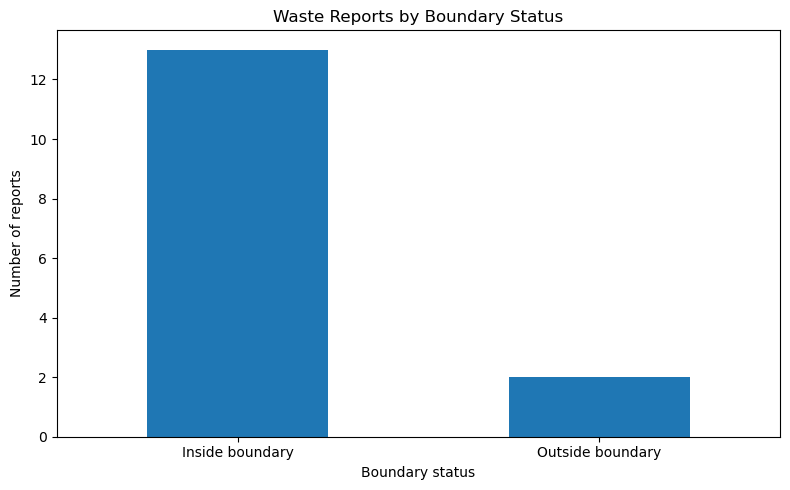

In [28]:
boundary_summary = df["boundary_status"].value_counts()

print("MZUZU SMARTCLEAN — BOUNDARY VALIDATION")
print("-" * 45)
print("Total reports:", len(df))
print("Inside boundary:", int(df["inside_boundary"].sum()))
print("Outside boundary:", int((~df["inside_boundary"]).sum()))

boundary_summary.plot(
    kind="bar",
    figsize=(8, 5),
    title="Waste Reports by Boundary Status",
    xlabel="Boundary status",
    ylabel="Number of reports",
    rot=0
)

plt.tight_layout()
plt.show()

In [29]:
from sklearn.cluster import DBSCAN

# Start by assigning every report the noise label
df["cluster"] = -1

# Select only reports inside the city polygon
inside_indices = df.index[df["inside_boundary"]]

if len(inside_indices) == 0:
    print("No reports fall inside the selected boundary.")
else:
    # Extract coordinates in latitude-longitude order
    valid_coordinates = df.loc[
        inside_indices, ["latitude", "longitude"]
    ].to_numpy()

    # Convert degrees to radians for Haversine distance
    valid_coordinates_radians = np.radians(valid_coordinates)

    # Initial demonstration parameters: 200 metres and 3 reports
    eps_metres = 200
    earth_radius_metres = 6_371_008.8
    eps_radians = eps_metres / earth_radius_metres
    min_samples = 3

    model = DBSCAN(
        eps=eps_radians,
        min_samples=min_samples,
        metric="haversine"
    )

    # Fit DBSCAN only to reports inside the boundary
    df.loc[inside_indices, "cluster"] = model.fit_predict(
        valid_coordinates_radians
    )

    # Give each report an understandable final status
    df["report_status"] = "Outside boundary"

    df.loc[
        df["inside_boundary"] & (df["cluster"] == -1),
        "report_status"
    ] = "Inside boundary - DBSCAN noise"

    df.loc[
        df["inside_boundary"] & (df["cluster"] >= 0),
        "report_status"
    ] = "Inside boundary - hotspot cluster"

    display(
        df[
            [
                "report_id",
                "boundary_status",
                "cluster",
                "report_status"
            ]
        ]
    )

,report_id,boundary_status,cluster,report_status
0,1,Inside boundary,0,Inside boundary - hotspot cluster
1,2,Inside boundary,0,Inside boundary - hotspot cluster
2,3,Inside boundary,0,Inside boundary - hotspot cluster
3,4,Inside boundary,0,Inside boundary - hotspot cluster
4,5,Inside boundary,0,Inside boundary - hotspot cluster
5,6,Inside boundary,1,Inside boundary - hotspot cluster
6,7,Inside boundary,1,Inside boundary - hotspot cluster
7,8,Inside boundary,1,Inside boundary - hotspot cluster
8,9,Inside boundary,1,Inside boundary - hotspot cluster
9,10,Inside boundary,1,Inside boundary - hotspot cluster
